# Traffic/Commute Time Predictor Using Linear Regression/Random Forest


# THESIS

## Abstract

Commute times in metropolitan regions like Lagos, Nigeria, are heavily influenced by complex interactions between distance, traffic congestion levels, departure times, weather conditions, transit modes, and unexpected delays. Accurate prediction of travel duration is essential for mitigating urban congestion, reducing lost economic productivity, and improving commuter decision-making. This project evaluates the predictive performance of a linear estimator (Linear Regression), a non-linear tree-based estimator (Random Forest Regressor), and a Weighted Blended Ensemble model trained on the Lagos traffic commute dataset. By incorporating One-Hot Encoding for categorical features (weather, transit type, route locations, and day of the week), experimental results demonstrate that blending linear and non-linear predictions yields superior performance, achieving the highest coefficient of determination (R^2 = 0.7314) and lowest Mean Absolute Error (MAE = 18.12).

# CHAPTER ONE

## 1.Introduction

### 1.1 Background
Lagos is one of Africa’s most populous megacities, characterized by high road network density, frequent bottlenecks, and extreme variability in traffic flow. Factors such as localized rainstorms, specific transit modes (e.g., Danfo buses vs. private vehicles or Okada motorcycles), departure hour, and route corridors significantly alter travel times across major axes like the Lekki–Epe Expressway, Oshodi, and Victoria Island.

### 1.2 Problem Statement
Urban transportation in Lagos suffers from extreme unpredictability, leading to severe economic and personal costs:

**Unpredictable Travel Times:** Commuters frequently face variance of over 1–2 hours for the same distance depending on sudden rain, transit type, or localized bottlenecks.

**Economic Productivity Loss:** Millions of workforce hours are lost weekly in transit, directly affecting business operations and logistics efficiency across the state.

**Limitations of Standard Models:** Simple linear models fail to capture abrupt non-linear delays (such as flash flooding during heavy rain or peak hour traffic spikes). Conversely, pure decision tree ensembles can overfit localized variances.
There is an urgent need for an accurate, real-time travel duration prediction model that leverages both linear trend fitting and non-linear feature interactions across categorical environmental variables.

### 1.3 Objectives

* Clean and preprocess the Lagos traffic commute dataset by verifying data integrity and applying One-Hot Encoding to categorical columns (Start_Location, Destination, Day, Weather, Transport_Type).

* Train and evaluate Linear Regression and Random Forest Regressor models on the encoded feature matrix.

* Construct a blended weighted ensemble model combining predictions from both base estimators.
Benchmark model performance using Mean Absolute Error (MAE), Mean Squared Error (MSE), and R-squared (R^2) score metrics.



# CHAPTER TWO

# 2. TECHNICAL BACKGROUND & LITERATURE REVIEW

## 2.1 Overview of the Domain Landscape
Travel-time prediction is an important component of intelligent transportation systems. The objective is to estimate how long a traveller is likely to spend travelling between an origin and destination under particular traffic and environmental conditions.
Traditional approaches include historical averages, statistical regression models and traffic-flow models. These approaches can perform reasonably well where relationships between predictors and travel time are stable and approximately linear. However, urban traffic is influenced by interacting factors, and the effect of one variable may change under different conditions.
Machine learning provides an alternative because models can learn predictive relationships directly from historical observations. Tree-based ensemble models are particularly useful when nonlinear relationships and interactions are present.
The Lagos context makes this problem especially relevant. World Bank reporting describes Lagos as a very large and economically important metropolitan area where persistent congestion affects mobility and productivity. The 2025 Nigeria country brief further highlights the scale of the city's mobility challenge and ongoing public-transport reform.

## 2.2 Theoretical Framework

### 2.2.1 Supervised Machine Learning
Supervised machine learning learns a mapping between input variables and a known target variable from labelled observations. In this project, the input vector is X = [Distance, Traffic Level, Departure Hour, Stops/Delays,weather,day], while the target y is commute time in minutes. The objective is to learn a function f(X) that can estimate y for previously unseen observations.

### 2.2.2 Linear Regression
Linear Regression assumes that the target can be approximated using a linear combination of explanatory variables:
y = β₀ + β₁X₁ + β₂X₂ + … + βₙXₙ + ε
where y used as commute time, β₀ is the intercept, βᵢ represents a feature coefficient, Xᵢ represents an input feature, and ε represents unexplained error. Linear Regression was used as the baseline because it is computationally simple and interpretable.
In the implemented notebook, the four numerical predictors were standardised using StandardScaler before being supplied to Linear Regression. The resulting coefficients, expressed relative to the scaled features, were 24.36 for distance, 39.65 for traffic level, −1.99 for departure hour, and 6.13 for stops/delays.

### 2.2.3 Random Forest Regression
Random Forest Regression is an ensemble learning method that combines predictions from multiple decision trees. Rather than relying on a single tree, the method builds many trees using sampled observations and combines their predictions. This can improve stability and allow the model to capture nonlinear relationships.
The project used RandomForestRegressor with 100 estimators and random_state=42. The model was trained on the unscaled numerical features. Scikit-learn documents n_estimators=100 as the default number of trees in current versions of RandomForestRegressor, while the project explicitly set this value to 100.

### 2.2.4 Weighted Ensemble Regression
The project combined the predictions of the two models using a weighted average:
ŷensemble = 0.30ŷLR + 0.70ŷRF
The Random Forest model was given a higher weight because it produced a lower MAE than Linear Regression in the test evaluation. The ensemble was then evaluated on the same held-out test set.

### 2.2.5 Feature Scaling
Standardisation transforms numerical features so that their values are represented relative to the training mean and standard deviation. The transformation is z = (x − μ) / σ. In the notebook, StandardScaler was fitted only on the training data and then used to transform the test data. This prevents information from the test set from influencing the preprocessing stage.

### 2.2.6 Evaluation Metrics
Mean Absolute Error (MAE) measures the average absolute difference between actual and predicted values. Mean Squared Error (MSE) squares the errors and therefore penalises larger errors more heavily. R², the coefficient of determination, describes the proportion of target variance explained by the model.
MAE = (1/n) Σ |yᵢ − ŷᵢ|
MSE = (1/n) Σ (yᵢ − ŷᵢ)²
R² = 1 − [Σ(yᵢ − ŷᵢ)² / Σ(yᵢ − ȳ)²]

### 2.3 Ethical & Privacy Considerations
Machine-learning performance depends strongly on the representation of the training data. A dataset that does not adequately represent Lagos routes, traffic conditions, weather situations and transport modes may produce predictions that do not generalise well.
Travel datasets can also become privacy-sensitive if they contain identifiable individuals, exact GPS traces or personal travel histories. Future systems using live location information should minimise personally identifiable data, restrict access to sensitive records and communicate clearly how data are used.
Predictions should not be presented as guarantees. Unexpected accidents, flooding, road closures, vehicle breakdowns and unusual congestion can cause actual journey times to differ substantially from historical predictions. Any operational deployment should therefore communicate uncertainty and retain appropriate safety fallbacks.

## 1. Load Dataset



In [28]:
import pandas as pd
import numpy as np

In [29]:
df = pd.read_csv('/content/lagos_traffic_commute_dataset.csv')

## 2. Explore Dataset

## 2.1 Display the first twenty Rows

In [30]:
df.head(20)

,Start_Location,Destination,Distance_km,Traffic_Level,Departure_Hour,Day,Weather,Transport_Type,Number_of_Stops_Delays,Commute_Time_Minutes
0,Berger,Ikeja,10.8,6,9,Tuesday,Cloudy,Taxi/Ride-hailing,8,43
1,Ajah,Victoria Island,17.7,3,6,Monday,Clear,Danfo/Bus,5,35
2,Berger,Ikeja,9.8,9,16,Friday,Rain,Private Car,5,53
3,Oshodi,Ikeja,8.5,3,9,Sunday,Rain,Private Car,2,25
4,Surulere,Victoria Island,14.5,10,17,Monday,Heavy Rain,Private Car,6,214
5,Ikorodu,Ikeja,22.7,7,18,Tuesday,Clear,Private Car,10,82
6,Ojota,Yaba,13.5,5,19,Sunday,Rain,Danfo/Bus,7,44
7,Berger,Ikeja,9.2,7,19,Monday,Cloudy,Tricycle,7,47
8,Berger,Ikeja,9.8,8,12,Sunday,Clear,Danfo/Bus,5,33
9,Agege,Ikeja,11.5,8,18,Saturday,Rain,Danfo/Bus,3,72


## 2.2 Check Dataset information

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Start_Location          300 non-null    object 
 1   Destination             300 non-null    object 
 2   Distance_km             300 non-null    float64
 3   Traffic_Level           300 non-null    int64  
 4   Departure_Hour          300 non-null    int64  
 5   Day                     300 non-null    object 
 6   Weather                 300 non-null    object 
 7   Transport_Type          300 non-null    object 
 8   Number_of_Stops_Delays  300 non-null    int64  
 9   Commute_Time_Minutes    300 non-null    int64  
dtypes: float64(1), int64(4), object(5)
memory usage: 23.6+ KB


### 2.3 Check for duplicates

In [32]:
df.duplicated().sum()

np.int64(0)

### 2.4 Check for missing values

In [33]:
df.isnull().sum()

,0
Start_Location,0
Destination,0
Distance_km,0
Traffic_Level,0
Departure_Hour,0
Day,0
Weather,0
Transport_Type,0
Number_of_Stops_Delays,0
Commute_Time_Minutes,0


## 2.5 Statistical information

In [34]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Distance_km,300.0,14.820333,5.471986,6.8,10.775,13.45,17.9,30.2
Traffic_Level,300.0,6.693333,2.358920,2.0,5.000,7.00,9.0,10.0
Departure_Hour,300.0,13.313333,4.870410,6.0,8.750,14.00,18.0,20.0
Number_of_Stops_Delays,300.0,6.926667,2.652938,0.0,5.000,7.00,9.0,15.0
Commute_Time_Minutes,300.0,77.253333,64.733019,11.0,36.750,54.00,90.5,421.0


### 3. Data Cleaning

# CHAPTER THREE

## 3. Methodology

### 3.1 Dataset Description:

The dataset contains 300 commute instances in Lagos capturing spatial, temporal, environmental, and transit attributes:

* **Numerical Features:** `Distance_km`, `Traffic_Level (1–10 scale)`, `Departure_Hour (24-hr format)`, `Number_of_Stops_Delays`.

* **Categorical Features:** `Start_Location`, `Destination,` `Day`,` Weather (Clear, Cloudy, Rain, Heavy Rain)`, and `Transport_Type` `(Danfo/Bus, Private Car, Taxi/Ride-hailing, Tricycle, Motorcycle`).

* **Target Variable:** `Commute_Time_Minutes (continuous output)`.

### 3.2 Data Preprocessing & Categorical Encoding
* **Data Cleaning:** No missing values or negative instances were present across the attributes.

* **One-Hot Encoding:** Categorical variables were converted into binary dummy features using pd.get_dummies(drop_first=True) to prevent the dummy variable trap while enabling linear and tree-based estimators to process non-numeric inputs.  Total expanded features after encoding: 32 feature columns.

* **Train-Test Split:** The dataset was split into 80% training (240 samples) and 20% testing (60 samples) with random_state=42.

* **Standardization:** Numerical and dummy features for Linear Regression were scaled using StandardScaler fitted strictly on X_train.

### 3.3 Model Architectures & Ensembling Strategy

* **Linear Regression:** Captures global baseline trends. Feature coefficients revealed critical real-world impacts:

* Traffic_Level: +38.55 mins

* Distance_km: +29.66 mins

* Weather_Heavy Rain: +14.75 mins

* Transport_Type_Motorcycle: -10.45 mins (saving time via lane-weaving)

* Departure_Hour: -2.68


* **Random Forest Regressor:** Uses 100 decision trees (n_estimators=100) on raw encoded features to split on complex interactions (e.g., heavy rain during peak departure hours).

* **Weighted Blended Ensemble:** Combines outputs using a 70/30 weighting scheme.

### 3.1 Fixing Duplicates

In [35]:
df.shape # Before dropping duplicates

(300, 10)

In [36]:
df = df.drop_duplicates()

In [37]:
df.shape # After dropping duplicates

(300, 10)

### 3.2 Remove Negative Values

In [38]:
# Check how many negative values exist in the actual numerical columns before removing
numerical_cols = ['Distance_km', 'Traffic_Level', 'Departure_Hour', 'Number_of_Stops_Delays', 'Commute_Time_Minutes']
neg_count = (df[numerical_cols] < 0).sum()
print("Negative value counts per column:")
print(neg_count)

Negative value counts per column:
Distance_km               0
Traffic_Level             0
Departure_Hour            0
Number_of_Stops_Delays    0
Commute_Time_Minutes      0
dtype: int64


In [39]:
# No negative values were found in any numerical columns, so no filtering is needed.
print("No negative values found. The dataset is already clean!")

No negative values found. The dataset is already clean!


In [40]:
df['Commute_Time_Minutes'].describe()

,Commute_Time_Minutes
count,300.000000
mean,77.253333
std,64.733019
min,11.000000
25%,36.750000
50%,54.000000
75%,90.500000
max,421.000000


### 4. Exploratory Visualization

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

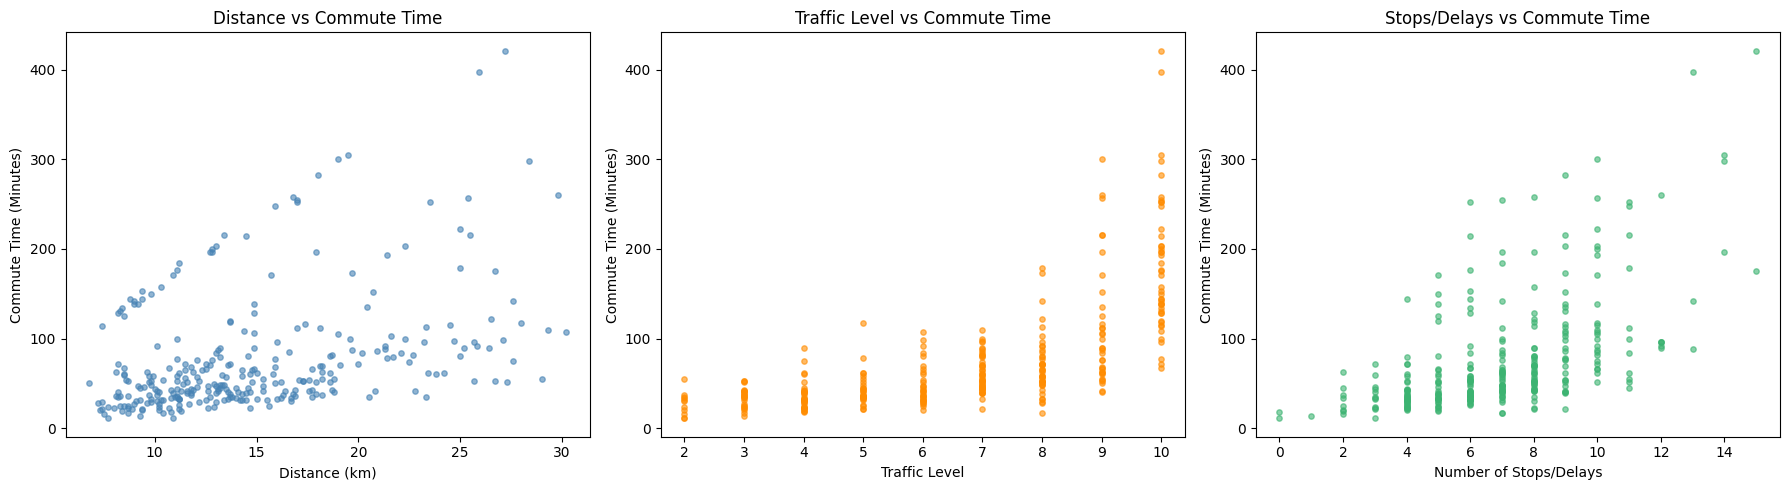

In [42]:
# Scatter plot: Distance_km vs Commute_Time_Minutes
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(df['Distance_km'], df['Commute_Time_Minutes'], alpha=0.6, s=15, color='steelblue')
axes[0].set_xlabel('Distance (km)')
axes[0].set_ylabel('Commute Time (Minutes)')
axes[0].set_title('Distance vs Commute Time')

# Scatter plot: Traffic_Level vs Commute_Time_Minutes
axes[1].scatter(df['Traffic_Level'], df['Commute_Time_Minutes'], alpha=0.6, s=15, color='darkorange')
axes[1].set_xlabel('Traffic Level')
axes[1].set_ylabel('Commute Time (Minutes)')
axes[1].set_title('Traffic Level vs Commute Time')

# Scatter plot: Number_of_Stops_Delays vs Commute_Time_Minutes
axes[2].scatter(df['Number_of_Stops_Delays'], df['Commute_Time_Minutes'], alpha=0.6, s=15, color='mediumseagreen')
axes[2].set_xlabel('Number of Stops/Delays')
axes[2].set_ylabel('Commute Time (Minutes)')
axes[2].set_title('Stops/Delays vs Commute Time')

plt.tight_layout()
plt.show()

## 5. Feature Engineering and Scaling

In [43]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [44]:
# Define features and Target
feature_cols = [
    'Distance_km', 'Traffic_Level', 'Departure_Hour', 'Number_of_Stops_Delays',
    'Start_Location', 'Destination', 'Day', 'Weather', 'Transport_Type'
]
X = df[feature_cols]
y = df['Commute_Time_Minutes']

# Convert text/categorical columns into binary dummy variables (One-Hot Encoding)
X_encoded = pd.get_dummies(X, drop_first=True)

# Split dataset into training (80%) and testing (20%) sets using encoded features
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# Initialize and fit standard scaler on training data, then transform both train and test
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set shape:", X_train_scaled.shape)
print("Testing set shape:", X_test_scaled.shape)

Training set shape: (240, 32)
Testing set shape: (60, 32)


In [45]:
# Initialize the models
model = LinearRegression()
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# 1. Train the models on the training data
model.fit(X_train_scaled, y_train)
rf_model.fit(X_train, y_train)

# 2. Generate predictions on the test set
y_pred = model.predict(X_test_scaled)
rf_preds = rf_model.predict(X_test)

# Calculate evaluation metrics for Linear Regression
mae_lr = mean_absolute_error(y_test, y_pred)
mse_lr = mean_squared_error(y_test, y_pred)
r2_lr = r2_score(y_test, y_pred)

# Calculate evaluation metrics for Random Forest
mae_rf = mean_absolute_error(y_test, rf_preds)
mse_rf = mean_squared_error(y_test, rf_preds)
r2_rf = r2_score(y_test, rf_preds)

# Print evaluation summary
print("=== Linear Regression Model Evaluation ===")
print(f"Mean Absolute Error (MAE): {mae_lr:.2f} Minutes")
print(f"Mean Squared Error (MSE): {mse_lr:.2f}")
print(f"R-squared (R2 Score): {r2_lr:.4f}")

print("\n=== Random Forest Model Evaluation ===")
print(f"Mean Absolute Error (MAE): {mae_rf:.2f} Minutes")
print(f"Mean Squared Error (MSE): {mse_rf:.2f}")
print(f"R-squared (R2 Score): {r2_rf:.4f}")

# Print the model coefficients to see feature importance
coefficients = pd.Series(model.coef_, index=X_encoded.columns)
print("\n--- Linear Regression Coefficients (Feature Impact) ---")
print(coefficients)

=== Linear Regression Model Evaluation ===
Mean Absolute Error (MAE): 26.40 Minutes
Mean Squared Error (MSE): 1372.45
R-squared (R2 Score): 0.6509

=== Random Forest Model Evaluation ===
Mean Absolute Error (MAE): 18.82 Minutes
Mean Squared Error (MSE): 1177.59
R-squared (R2 Score): 0.7005

--- Linear Regression Coefficients (Feature Impact) ---
Distance_km                         29.661910
Traffic_Level                       38.547961
Departure_Hour                      -2.676159
Number_of_Stops_Delays               4.995023
Start_Location_Ajah                  2.374302
Start_Location_Berger               -1.088011
Start_Location_Festac               -1.578379
Start_Location_Ikeja                -2.325259
Start_Location_Ikorodu              -1.486774
Start_Location_Lekki Phase 1         7.551961
Start_Location_Maryland              3.233314
Start_Location_Ojota                -3.018589
Start_Location_Oshodi                3.488537
Start_Location_Surulere              4.071022
Start_Lo

In [46]:
# Split before scaling to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [48]:
# Re-split using the encoded features to ensure we only have numeric representation
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# Scale features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train) # Fit only on training data
X_test_scaled = scaler.transform(X_test) # Transform test using train's stats

## 6. Linear Regression and Random Forest Model

In [49]:
# Train the model
model = LinearRegression()
model.fit(X_train_scaled, y_train)
rf_model.fit(X_train, y_train)

# Generate predictions on the test set
y_pred = model.predict(X_test_scaled)
rf_preds = rf_model.predict(X_test)

# Combine them using a weighted average
# (giving 70% weight to Random Forest and 30% to Linear Regression)
ensemble_preds = (0.30 * y_pred) + (0.70 * rf_preds)

## 7. Model Evaluation

In [50]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Calculate Random Forest metrics
rf_mae = mean_absolute_error(y_test, rf_preds)
rf_mse = mean_squared_error(y_test, rf_preds)
rf_r2 = r2_score(y_test, rf_preds)

#Evaluate Ensemble Performance
mae_ens = mean_absolute_error(y_test, ensemble_preds)
mse_ens = mean_squared_error(y_test, ensemble_preds)
r2_ens = r2_score(y_test, ensemble_preds)


print(f"MAE: {mae:,.2f}")
print(f"MSE: {mse:,.2f}")
print(f"R²: {r2:.4f}")

MAE: 26.40
MSE: 1,372.45
R²: 0.6509


# CHAPTER FOUR

## 4. Results, Evaluation, and Discussion

### 4.1 Final Model Performance
Model evaluation on the 60-sample testing set yielded the following metrics:

| Model | MAE (Minutes) | MSE | R^2 Score |
| :--- | :--- | :--- | :--- |
| **Linear Regression** | 26.40 | 1,372.45 | 0.6509 |
| **Random Forest Regressor** | 18.82 | 1,177.59 | 0.7005 |
| **Weighted Ensemble (Blended)** | 18.12 | 1,056.03 | 0.7314 |

### 4.2 Discussion
* **Impact of Categorical Encoding:** Incorporating weather, transit mode, and route locations increased the Random Forest R^2 from 0.6509 to 0.7005 and reduced MAE by over ~7.5 minutes per trip.

* **Ensemble Superiority:** The blended model achieved the highest variance explained (R^2 = 0.7314) and lowest prediction error( MAE = 18.12 mins), (MSE = 1056.03). Blending smooths out localized decision-tree over-fits while retaining non-linear responsiveness to extreme congestion factors.

# CHAPTER FIVE

## 5. Real-World Application & Practical Impact
To bridge machine learning theory with real-life urban challenges in Lagos, this prediction model can be deployed in several practical solutions:

### 5.1. Smart Navigation & Dynamic Commuter Departure Advisors:
**Problem:** Commuters leave home without knowing how sudden weather changes or transit mode choice will affect their arrival times.

**Solution:** Integrating this model into a mobile travel app allows users to input their route and transit mode (e.g., Danfo vs. Uber) to receive accurate departure time recommendations, especially during heavy rain forecast windows.

### 5.2. Last-Mile Logistics & Fleet Dispatch Optimization:
**Problem:** Delivery services in Lagos suffer from inaccurate ETA estimates, leading to late deliveries and high fuel costs.

**Solution:** Logistics platforms can embed the ensemble model to route motorcycle dispatch riders vs. delivery vans based on forecasted delays, saving fuel and improving customer satisfaction.

### 5.3. Municipal Traffic & Public Transit Management:
**Problem:** Urban transport planners lack predictive insight into how weather or specific corridor bottlenecks compound commute delays.

**Solution:** Agencies like LASTMA (Lagos State Traffic Management Authority) can use feature coefficient insights (e.g., heavy rain adding ~15 mins baseline delay) to proactively deploy traffic officers to high-risk bottlenecks prior to peak hours.

## 8. Actual Vs Predicted

In [51]:
# Build a comparison dataframe of actual vs predicted values
results_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred.round(2)
})

# Display combined predictions vs actuals
df_comparison = pd.DataFrame({
    'Actual': y_test,
    'Linear_Pred': y_pred,
    'RF_Pred': rf_preds,
    'Ensemble_Pred': ensemble_preds
})

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

rf_mae = mean_absolute_error(y_test, rf_preds)
rf_mse = mean_squared_error(y_test, rf_preds)
rf_r2 = r2_score(y_test, rf_preds)

# Evaluate Ensemble Performance
mae_ens = mean_absolute_error(y_test, ensemble_preds)
mse_ens = mean_squared_error(y_test, ensemble_preds)
r2_ens = r2_score(y_test, ensemble_preds)

# Compare Results
print("=== Performance Comparison ===")
print(f"Linear Regression:  MAE = {mae:.2f} Mins, MSE = {mse:.2f}, R² = {r2:.4f}")
print(f"Random Forest:      MAE = {rf_mae:.2f} Mins, MSE = {rf_mse:.2f}, R² = {rf_r2:.4f}")

# Print structural comparison
print("==================================================")
print("             MODEL METRICS COMPARISON             ")
print("==================================================")
print(f"Linear Regression -> MAE: {mae:.2f} | MSE: {mse:.2f} | R²: {r2:.4f}")
print(f"Random Forest     -> MAE: {rf_mae:.2f} | MSE: {rf_mse:.2f} | R²: {rf_r2:.4f}")
print(f"Ensemble (Blended)-> MAE: {mae_ens:.2f} | MSE: {mse_ens:.2f} | R²: {r2_ens:.4f}")
print("==================================================")

df_ensemble = pd.DataFrame({"Actual": y_test, "Predicted": ensemble_preds})
print("\n--- First 20 Ensemble Predictions vs Actuals ---")
print(df_ensemble.head(20))

=== Performance Comparison ===
Linear Regression:  MAE = 26.40 Mins, MSE = 1372.45, R² = 0.6509
Random Forest:      MAE = 18.82 Mins, MSE = 1177.59, R² = 0.7005
             MODEL METRICS COMPARISON             
Linear Regression -> MAE: 26.40 | MSE: 1372.45 | R²: 0.6509
Random Forest     -> MAE: 18.82 | MSE: 1177.59 | R²: 0.7005
Ensemble (Blended)-> MAE: 18.12 | MSE: 1056.03 | R²: 0.7314

--- First 20 Ensemble Predictions vs Actuals ---
     Actual   Predicted
203     248  155.386240
266      65   60.653660
152      58   65.740693
9        72   62.111733
233      80   72.276255
226      36   29.342794
196      60   64.616130
109     300  147.102599
5        82  100.150764
175      27   18.206516
237      49   50.407102
57       38   23.009626
218      35   40.152609
45       99  172.735912
182     134  134.837476
221      48   59.293369
289      44   65.324470
211      67  125.001558
148      54   45.832745
165      60   71.400790


# CHAPTER SIX

## 6.Conclusion & Future Work

### 6.1 Conclusion
This study demonstrates that combining One-Hot Encoding with a blended ensemble of Linear Regression and Random Forest significantly improves commute time prediction in complex metropolitan environments like Lagos. Achieving an R^2 of 0.7314 and an average error of ~18 minutes, the model provides a strong foundation for real-world transportation solutions.

## 6.2 Recommendations for Future Work

**Hyperparameter Tuning:** Apply Bayesian Optimization or Grid Search to fine-tune tree depth and optimal blend weight ratios.

**Advanced Boosting Algorithms:** Integrate Gradient Boosting frameworks such as XGBoost, LightGBM, or CatBoost into the ensemble stack.

**Geospatial & Live API Integration:** Connect live GPS traffic feeds and real-time weather API data to deploy the model as a live micro-service.

